In [1]:
import sys
import gymnasium as gym
import gymnasium_2048
import numpy as np
import time


In [ ]:
env = gym.make(
    "gymnasium_2048:gymnasium_2048/TwentyFortyEight-v0",
    render_mode="human",
)

observation, info = env.reset()
score = 0
done = False

try:
    while not done:
        
        time.sleep(0.15) 
        action = env.action_space.sample()
        observation, reward, terminated, truncated, info = env.step(action)

        score += reward
        done = terminated or truncated

    print(f"Final score: {score}")
    time.sleep(20) 

finally:
    env.close()

Final score: 908


In [20]:
def display_observation(observation):
    powers = observation.argmax(axis=-1)
    board = np.where(powers == 0, 0, 2 ** powers)
    print(board)
env = gym.make(
    "gymnasium_2048:gymnasium_2048/TwentyFortyEight-v0",)

observation, info = env.reset()
display_observation(observation)

for i in range(10):
   observation, reward, terminated, truncated, info = env.step(1)
   display_observation(observation)

[[0 0 0 0]
 [0 0 0 0]
 [0 0 2 0]
 [0 0 2 0]]
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 2]
 [2 0 0 2]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 2]
 [0 0 0 4]]


In [2]:
from dataclasses import dataclass, field
from copy import deepcopy
import numpy as np


@dataclass
class NodeGene:
    id: int
    kind: str
    depth: float
    activation: str = "sigmoid"


@dataclass
class ConnectionGene:
    innovation: int
    source: int
    target: int
    weight: float
    enabled: bool = True


In [3]:
class InnovationTracker:
    def __init__(self, node_counter):
        self.node_counter = node_counter
        self.connection_counter = 0
        self.connections = {}  # (source, target) -> innovation ID
        self.splits = {}       # original innovation -> new node ID
        self.node_depths = {}

    def connection_id(self, source, target):
        key = (source, target)

        if key not in self.connections:
            self.connections[key] = self.connection_counter
            self.connection_counter += 1

        return self.connections[key]

    def split_node_id(self, connection_id):
        if connection_id not in self.splits:
            self.splits[connection_id] = self.node_counter
            self.node_counter += 1

        return self.splits[connection_id]

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
class Genome:
    def __init__(self, input_ids=range(16), output_ids=range(16, 20),
                bias_id=20):
        self.input_ids = tuple(input_ids)
        self.output_ids = tuple(output_ids)
        self.bias_id = bias_id
        self.nodes = {}
        self.connections = {}
        self.evaluation_order = []
        self.incoming = {}

    def init_genome(self, tracker, rng):
        self.nodes.clear()
        self.connections.clear()
        self.evaluation_order.clear()
        self.incoming.clear()

        for node_id in self.input_ids:
            self.nodes[node_id] = NodeGene(
                id=node_id, kind="input", activation="identity",depth=0.0
            )

        self.nodes[self.bias_id] = NodeGene(
            id=self.bias_id, kind="bias", activation="identity",depth=0.0
        )

        for node_id in self.output_ids:
            self.nodes[node_id] = NodeGene(
                id=node_id, kind="output", depth=1, activation="sigmoid"
            )

        self.evaluation_order = list(self.output_ids)
        self.incoming = {node_id: [] for node_id in self.nodes}

        sources = list(self.input_ids) + [self.bias_id]

        for source in sources:
            for target in self.output_ids:
                innovation = tracker.connection_id(source, target)

                connection = ConnectionGene(
                    innovation=innovation,
                    source=source,
                    target=target,
                    weight=float(rng.normal(0, 1)),
                )

                self.connections[innovation] = connection
                self.incoming[target].append(connection)

    def mutate_weights(self, rng, probability=0.8,
                    perturb_probability=0.9,
                    perturb_scale=0.2,
                    replacement_scale=1.0):
        # One decision for the entire genome.
        if rng.random() >= probability:
            return

        for connection in self.connections.values():
            if rng.random() < perturb_probability:
                connection.weight += float(
                    rng.uniform(-perturb_scale, perturb_scale)
                )
            else:
                connection.weight = float(
                    rng.normal(0, replacement_scale)
                )

    def add_node(self, tracker, rng):
        """Split one enabled non-bias connection."""
        candidates = [
            connection
            for connection in self.connections.values()
            if connection.enabled
            and connection.source != self.bias_id
        ]

        if not candidates:
            return False

        old = candidates[int(rng.integers(len(candidates)))]
        node_id = tracker.split_node_id(old.innovation)

        if node_id in self.nodes:
            return False

        source_depth = self.nodes[old.source].depth
        target_depth = self.nodes[old.target].depth
        depth = (source_depth + target_depth) / 2

        if not source_depth < depth < target_depth:
            return False

        # Disable the original connection and remove it from active inputs.
        old.enabled = False
        self.incoming[old.target].remove(old)

        self.nodes[node_id] = NodeGene(
            id=node_id,
            kind="hidden",
            depth=depth,
            activation="sigmoid",
        )

        # Evaluate the new node before its target.
        target_index = self.evaluation_order.index(old.target)
        self.evaluation_order.insert(target_index, node_id)

        self.incoming[node_id] = []

        for source, target, weight in [
            (old.source, node_id, 1.0),
            (node_id, old.target, old.weight),
            (self.bias_id, node_id, 0.0),
        ]:
            innovation = tracker.connection_id(source, target)

            connection = ConnectionGene(
                innovation=innovation,
                source=source,
                target=target,
                weight=weight,
            )

            self.connections[innovation] = connection
            self.incoming[target].append(connection)

        return True

    def add_connection(self, tracker, rng):
        existing = {
            (c.source, c.target): c
            for c in self.connections.values()
        }

        candidates = [
            (source.id, target.id)
            for source in self.nodes.values()
            for target in self.nodes.values()
            if source.depth < target.depth
            and target.kind not in ("input", "bias")
            and (
                (source.id, target.id) not in existing
                or not existing[(source.id, target.id)].enabled
            )
        ]

        if not candidates:
            return False

        source, target = candidates[int(rng.integers(len(candidates)))]
        connection = existing.get((source, target))

        if connection is not None:
            # Re-enable the stored gene, preserving its weight and ID.
            connection.enabled = True
        else:
            innovation = tracker.connection_id(source, target)

            connection = ConnectionGene(
                innovation=innovation,
                source=source,
                target=target,
                weight=float(rng.normal(0, 1)),
            )

            self.connections[innovation] = connection

        self.incoming[target].append(connection)

        self.evaluation_order.sort(
            key=lambda node_id: (self.nodes[node_id].depth, node_id)
        )

        return True
    
    def mutate(self, tracker, rng,
           weight_probability=0.8,
           add_node_probability=0.03,
           add_connection_probability=0.05):

        self.mutate_weights(rng, probability=weight_probability)

        if rng.random() < add_node_probability:
            self.add_node(tracker, rng)

        if rng.random() < add_connection_probability:
            self.add_connection(tracker, rng)

    def activate(self, inputs):
        inputs = np.asarray(inputs, dtype=float)

        if inputs.shape != (len(self.input_ids),):
            raise ValueError(
                f"Expected {len(self.input_ids)} inputs, got {inputs.shape}"
            )

        values = dict(zip(self.input_ids, inputs))
        values[self.bias_id] = 1.0

        for node_id in self.evaluation_order:
            total = sum(
                connection.weight * values[connection.source]
                for connection in self.incoming[node_id]
            )

            activation = self.nodes[node_id].activation

            if activation == "sigmoid":
                z = 4.9 * total

                if z >= 0:
                    value = 1.0 / (1.0 + np.exp(-z))
                else:
                    exp_z = np.exp(z)
                    value = exp_z / (1.0 + exp_z)

            elif activation == "tanh":
                value = np.tanh(total)

            elif activation == "identity":
                value = total

            else:
                raise ValueError(f"Unknown activation: {activation}")

            values[node_id] = float(value)

        return np.array([
            values[node_id] for node_id in self.output_ids
        ])
    
    def compatibility_distance(self, other, c_structure=1.0, c_weight=0.4):
        ids_a = set(self.connections)
        ids_b = set(other.connections)

        matching = ids_a & ids_b
        unmatched_count = len(ids_a ^ ids_b)

        if matching:
            mean_weight_difference = sum(
                abs(
                    self.connections[innovation].weight
                    - other.connections[innovation].weight
                )
                for innovation in matching
            ) / len(matching)
        else:
            mean_weight_difference = 0.0

        n = max(len(ids_a), len(ids_b))
        if n < 20:
            n = 1

        return (
            c_structure * unmatched_count / n
            + c_weight * mean_weight_difference
        )




def plot_genome(genome, title="Genome", show_disabled=False):
    colors = {
        "input": "#60a5fa",
        "bias": "#fbbf24",
        "hidden": "#a78bfa",
        "output": "#34d399",
    }

    # Group nodes by depth.
    layers = {}
    for node in genome.nodes.values():
        layers.setdefault(node.depth, []).append(node.id)

    positions = {}
    for depth, node_ids in layers.items():
        node_ids.sort()
        ys = np.linspace(0.95, 0.05, len(node_ids))
        if len(node_ids) == 1:
            ys = [0.5]

        for node_id, y in zip(node_ids, ys):
            positions[node_id] = (depth, y)

    connections = [
        c for c in genome.connections.values()
        if c.enabled or show_disabled
    ]

    max_weight = max(
        (abs(c.weight) for c in connections if c.enabled),
        default=1.0,
    )
    max_weight = max(max_weight, 1e-12)

    fig, ax = plt.subplots(figsize=(13, 9))

    # Draw edges behind the nodes.
    for c in connections:
        color = (
            "#94a3b8" if not c.enabled
            else "#2563eb" if c.weight >= 0
            else "#dc2626"
        )

        edge = FancyArrowPatch(
            positions[c.source],
            positions[c.target],
            arrowstyle="-|>",
            mutation_scale=9,
            shrinkA=13,
            shrinkB=13,
            linewidth=0.5 + 2.5 * abs(c.weight) / max_weight
                      if c.enabled else 0.7,
            color=color,
            alpha=0.4 if c.enabled else 0.2,
            linestyle="-" if c.enabled else "--",
            zorder=1,
        )
        ax.add_patch(edge)

    # Label board inputs by cell and outputs by direction.
    labels = {
        node_id: f"{i // 4},{i % 4}"
        for i, node_id in enumerate(genome.input_ids)
    }
    labels[genome.bias_id] = "bias"

    for node_id, direction in zip(
        genome.output_ids, ["up", "right", "down", "left"]
    ):
        labels[node_id] = direction

    for node in genome.nodes.values():
        x, y = positions[node.id]

        ax.scatter(
            x, y,
            s=420,
            color=colors[node.kind],
            edgecolors="white",
            linewidths=1.5,
            zorder=3,
        )

        ax.annotate(
            labels.get(node.id, str(node.id)),
            (x, y),
            xytext=(0, 16),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            zorder=4,
        )

    legend = [
        Line2D(
            [0], [0], marker="o", linestyle="",
            markerfacecolor=color, markeredgecolor="white",
            markersize=10, label=kind.capitalize(),
        )
        for kind, color in colors.items()
    ]
    legend += [
        Line2D([0], [0], color="#2563eb", label="Positive weight"),
        Line2D([0], [0], color="#dc2626", label="Negative weight"),
    ]

    ax.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),
        ncol=3,
        frameon=False,
    )

    ax.set_title(title, fontsize=15, pad=20)
    ax.set_xlabel("Node depth")
    ax.set_xlim(-0.08, 1.08)
    ax.set_ylim(-0.03, 1.08)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout()
    plt.show()

    return fig, ax

In [29]:
@dataclass
class Species:
    id: int
    representative: Genome
    members: list[int]

class Population:
    def __init__(self, size, tracker, rng, compatibility_threshold=0.5):
        self.tracker = tracker
        self.rng = rng
        self.compatibility_threshold = compatibility_threshold

        self.genomes = {}
        self.fitness = {}
        self.species = {}
        self.generation = 0

        self.genome_counters = 0
        self.species_counters = 0

        for _ in range(size):
            genome = Genome()
            genome.init_genome(self.tracker, self.rng)

            genome_id = self.genome_counters
            self.genome_counters += 1
            self.genomes[genome_id] = genome

        self.assign_species()

    def assign_species(self):
        # Keep representatives, but clear the previous membership.
        for species in self.species.values():
            species.members.clear()

        for genome_id, genome in self.genomes.items():
            for species in self.species.values():
                distance = genome.compatibility_distance(
                    species.representative
                )

                if distance < self.compatibility_threshold:
                    species.members.append(genome_id)
                    break
            else:
                # No representative matched: create a species.
                species_id = self.species_counters
                self.species_counters += 1

                self.species[species_id] = Species(
                    id=species_id,
                    representative=genome,
                    members=[genome_id],
                )

        # Remove empty species.
        self.species = {
            species_id: species
            for species_id, species in self.species.items()
            if species.members
        }

        # Choose a current member as each species' next representative.
        for species in self.species.values():
            index = int(self.rng.integers(len(species.members)))
            genome_id = species.members[index]
            species.representative = deepcopy(self.genomes[genome_id])

    def evaluate(self, env, seeds):
        seeds = tuple(seeds)

        if not seeds:
            raise ValueError("Provide at least one evaluation seed.")

        self.fitness.clear()

        for genome_id, genome in self.genomes.items():
            agent = Agent(genome)

            scores = [
                agent.play(env, seed=int(seed))["score"]
                for seed in seeds
            ]

            self.fitness[genome_id] = float(np.mean(scores))

    def adjusted_fitness(self):
        adjusted = {}

        for genome_id, genome in self.genomes.items():
            close_count = sum(
                genome.compatibility_distance(other)
                < self.compatibility_threshold
                for other in self.genomes.values()
            )

            adjusted[genome_id] = (
                self.fitness[genome_id] / close_count
            )

        return adjusted


    # def adjusted_fitness(self):
    #     adjusted = {}

    #     for species in self.species.values():
    #         species_size = len(species.members)

    #         for genome_id in species.members:
    #             adjusted[genome_id] = (
    #                 self.fitness[genome_id] / species_size
    #             )

    #     return adjusted


    def reproduce(self, survival_fraction=0.5):
        if not 0 < survival_fraction <= 1:
            raise ValueError("survival_fraction must be in (0, 1].")

        if not self.genomes:
            raise ValueError("The population is empty.")

        if set(self.fitness) != set(self.genomes):
            raise ValueError("Evaluate the whole population first.")

        species_list = list(self.species.values())
        population_size = len(self.genomes)

        fitness_values = np.array(list(self.fitness.values()), dtype=float)
        if (
            not np.all(np.isfinite(fitness_values))
            or np.any(fitness_values < 0)
        ):
            raise ValueError("Fitness must be finite and nonnegative.")

        adjusted = self.adjusted_fitness()

        # Species receive offspring proportional to summed adjusted fitness.
        species_scores = np.array([
            sum(adjusted[g] for g in species.members)
            for species in species_list
        ])

        if species_scores.sum() == 0:
            shares = np.full(len(species_list), 1 / len(species_list))
        else:
            shares = species_scores / species_scores.sum()

        # Convert fractional allocations into exactly population_size slots.
        expected = population_size * shares
        allocations = np.floor(expected).astype(int)
        remaining = population_size - int(allocations.sum())

        shuffled = self.rng.permutation(len(species_list))
        ranked_remainders = sorted(
            shuffled,
            key=lambda i: expected[i] - allocations[i],
            reverse=True,
        )

        for index in ranked_remainders[:remaining]:
            allocations[index] += 1

        new_genomes = {}

        for species, offspring_count in zip(species_list, allocations):
            original_size = len(species.members)

            # Eliminate the lowest-performing members from the parent pool.
            ranked_members = sorted(
                species.members,
                key=lambda g: self.fitness[g],
                reverse=True,
            )

            keep_count = max(
                1,
                int(np.ceil(original_size * survival_fraction)),
            )
            species.members = ranked_members[:keep_count]

            if offspring_count == 0:
                continue

            # Paper's elitism condition: species originally had >5 members.
            preserve_champion = original_size > 5

            for index in range(offspring_count):
                elite = preserve_champion and index == 0

                if elite:
                    parent_id = species.members[0]
                else:
                    parent_index = int(
                        self.rng.integers(len(species.members))
                    )
                    parent_id = species.members[parent_index]

                child = deepcopy(self.genomes[parent_id])

                if not elite:
                    child.mutate(self.tracker, self.rng)

                genome_id = self.genome_counters
                self.genome_counters += 1
                new_genomes[genome_id] = child

        # Replace parents with offspring.
        self.genomes = new_genomes
        self.fitness.clear()
        self.generation += 1
        self.assign_species()
        


In [ ]:
class Agent:
    def __init__(self, genome,max_pow=16):
        self.genome = genome
        self.max_pow = max_pow

    def encode_board(self, observation):
        powers = observation.argmax(axis=-1)
        return 2*powers.astype(float).flatten() / (self.max_pow-1)-1

    def legal_moves(self, observation):
        board = observation.argmax(axis=-1)

        def can_move_left(rows):
            for row in rows:
                occupied = np.flatnonzero(row)

                # Tiles can slide toward an empty space.
                if not np.array_equal(occupied, np.arange(len(occupied))):
                    return True

                # Consecutive occupied tiles can merge.
                tiles = row[occupied]
                if np.any(tiles[:-1] == tiles[1:]):
                    return True

            return False

        return np.array([
            can_move_left(board.T),          # 0: up
            can_move_left(board[:, ::-1]),    # 1: right
            can_move_left(board.T[:, ::-1]),  # 2: down
            can_move_left(board),            # 3: left
        ], dtype=bool)

    def choose_action(self, observation):
        legal = self.legal_moves(observation)

        if not legal.any():
            return None

        inputs = self.encode_board(observation)
        scores = np.array(
            self.genome.activate(inputs), dtype=float, copy=True
        )

        if scores.shape != (4,):
            raise ValueError("The genome must produce four move scores.")

        scores[~legal] = -np.inf
        return int(np.argmax(scores))

    def play(self, env, seed=None, show_board=False, delay=0):
        import time

        observation, info = env.reset(seed=seed)
        score = 0
        moves = 0

        if show_board:
            self.print_board(observation)

        while True:
            action = self.choose_action(observation)

            if action is None:
                break

            observation, reward, terminated, truncated, info = env.step(action)

            score += reward
            moves += 1

            if show_board:
                direction = ["up", "right", "down", "left"][action]
                print(f"\nMove {moves}: {direction}")
                self.print_board(observation)

            if delay > 0:
                time.sleep(delay)

            if terminated or truncated:
                break
        if delay > 0:
            time.sleep(delay*10)          
        return {
            "score": score,
            "moves": moves,
            "observation": observation,
        }

    @staticmethod
    def print_board(observation):
        powers = observation.argmax(axis=-1)
        board = np.where(powers == 0, 0, 2 ** powers)
        print(board)

In [6]:
# Create a random genome.
rng = np.random.default_rng(0)

tracker = InnovationTracker(node_counter=21)

genome = Genome()
genome.init_genome(tracker, rng)

# Create the agent and game window.
agent = Agent(genome)

env = gym.make(
    "gymnasium_2048:gymnasium_2048/TwentyFortyEight-v0",
    render_mode="human",
)

# Play with a short delay between moves.
try:
    result = agent.play(env, seed=0, delay=0.1)

    print("Score:", result["score"])
    print("Moves:", result["moves"])
finally:
    env.close()

Score: 712
Moves: 92


In [16]:
rng = np.random.default_rng(0)

tracker = InnovationTracker(node_counter=21)

genome = Genome()
genome.init_genome(tracker, rng)

Generation   0 | Best:   4220.8 | Mean:   1946.8 | Species: 1
Generation   1 | Best:   4373.6 | Mean:   2292.6 | Species: 1
Generation   2 | Best:   4373.6 | Mean:   2539.6 | Species: 1
Generation   3 | Best:   4373.6 | Mean:   2598.9 | Species: 1
Generation   4 | Best:   4373.6 | Mean:   2549.0 | Species: 1
Generation   5 | Best:   4373.6 | Mean:   2728.8 | Species: 1
Generation   6 | Best:   4373.6 | Mean:   2589.0 | Species: 1
Generation   7 | Best:   4373.6 | Mean:   2568.1 | Species: 1
Generation   8 | Best:   4373.6 | Mean:   2524.6 | Species: 1
Generation   9 | Best:   4373.6 | Mean:   2375.3 | Species: 1
Generation  10 | Best:   4373.6 | Mean:   2610.3 | Species: 1
Generation  11 | Best:   4373.6 | Mean:   2429.3 | Species: 1
Generation  12 | Best:   4567.2 | Mean:   2499.6 | Species: 1
Generation  13 | Best:   4567.2 | Mean:   2497.7 | Species: 1
Generation  14 | Best:   4567.2 | Mean:   2617.3 | Species: 1
Generation  15 | Best:   4948.0 | Mean:   2694.9 | Species: 1
Generati

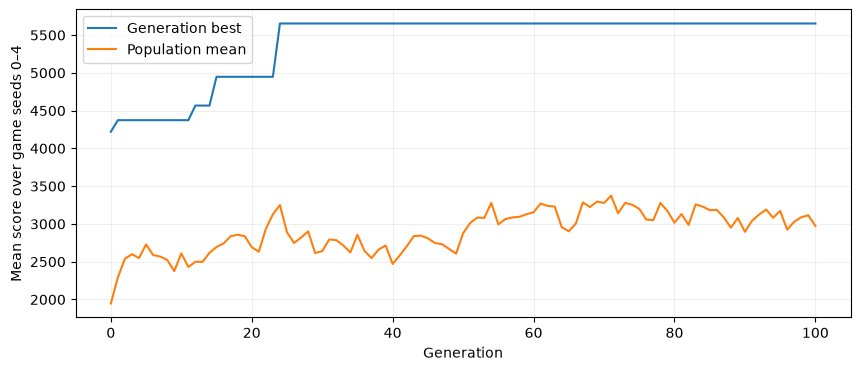

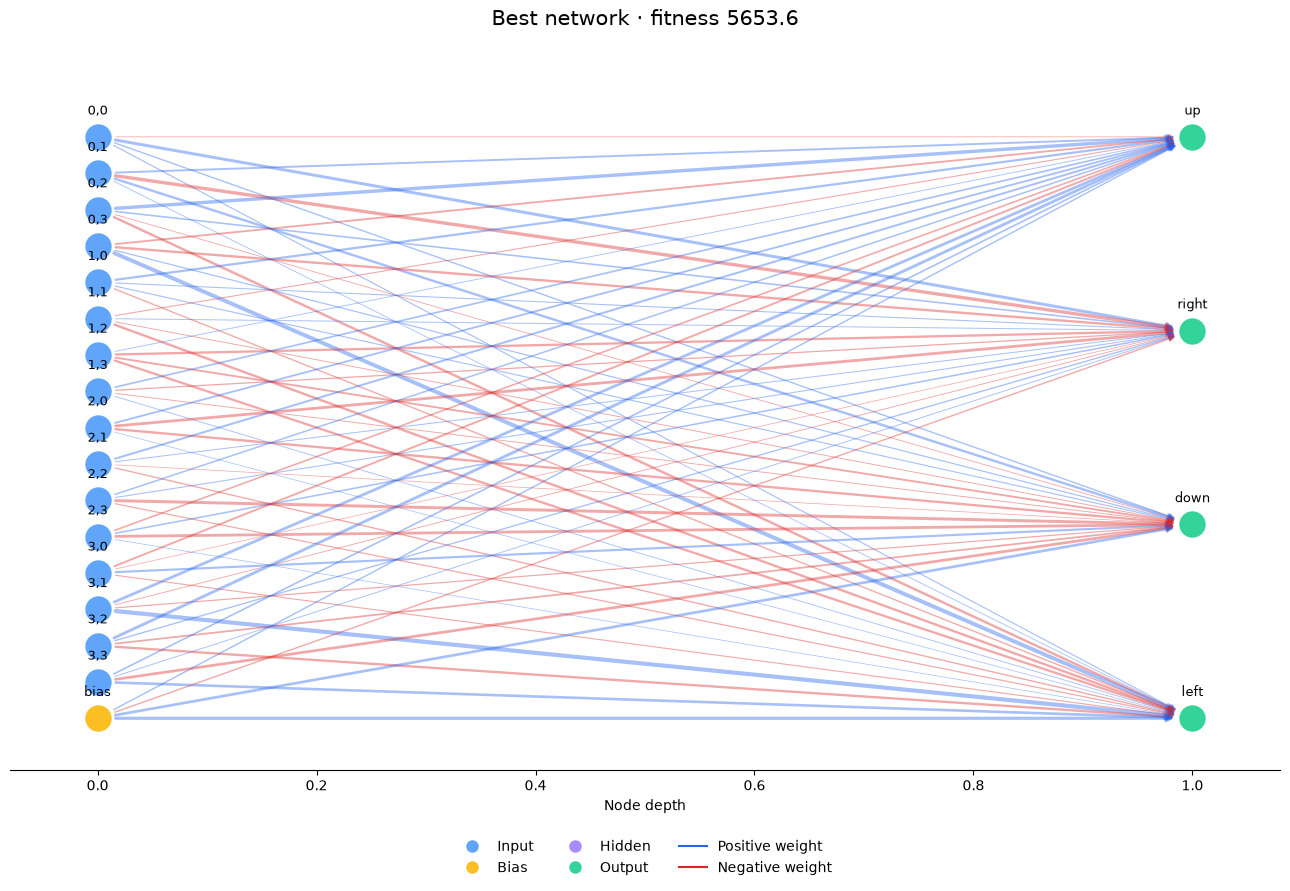

(<Figure size 1300x900 with 1 Axes>,
 <Axes: title={'center': 'Best network · fitness 5653.6'}, xlabel='Node depth'>)

In [30]:
from copy import deepcopy

rng = np.random.default_rng(0)
tracker = InnovationTracker(node_counter=21)

population = Population(
    size=50,
    tracker=tracker,
    rng=rng,
    compatibility_threshold=3.0,
)

history = []
best_ever_genome = None
best_ever_fitness = -np.inf

env = gym.make(
    "gymnasium_2048:gymnasium_2048/TwentyFortyEight-v0"
)

try:
    # Evaluate generation 0, then evolve and evaluate generations 1–100.
    for generation in range(101):
        if generation > 0:
            population.reproduce(survival_fraction=0.5)

        population.evaluate(env, seeds=range(5))

        best_id = max(population.fitness, key=population.fitness.get)
        best_fitness = population.fitness[best_id]
        mean_fitness = float(np.mean(list(population.fitness.values())))

        if best_fitness > best_ever_fitness:
            best_ever_fitness = best_fitness
            best_ever_genome = deepcopy(population.genomes[best_id])

        history.append({
            "generation": population.generation,
            "best": best_fitness,
            "mean": mean_fitness,
            "species": len(population.species),
        })

        print(
            f"Generation {population.generation:3d} | "
            f"Best: {best_fitness:8.1f} | "
            f"Mean: {mean_fitness:8.1f} | "
            f"Species: {len(population.species)}"
        )

finally:
    env.close()


fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    [h["generation"] for h in history],
    [h["best"] for h in history],
    label="Generation best",
)
ax.plot(
    [h["generation"] for h in history],
    [h["mean"] for h in history],
    label="Population mean",
)

ax.set_xlabel("Generation")
ax.set_ylabel("Mean score over game seeds 0–4")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

plot_genome(
    best_ever_genome,
    title=f"Best network · fitness {best_ever_fitness:.1f}",
)

In [31]:
hidden_counts = [
    sum(node.kind == "hidden" for node in genome.nodes.values())
    for genome in population.genomes.values()
]

print("Genomes with hidden nodes:", sum(n > 0 for n in hidden_counts))
print("Maximum hidden nodes:", max(hidden_counts))
print("Recorded node splits:", len(tracker.splits))

Genomes with hidden nodes: 45
Maximum hidden nodes: 4
Recorded node splits: 57
